### Assignment 1 (4 scores):

- Use Numpy only to construct the Logistic Regression model.
- Train and evaluating (precision, recall, f1) the Logistic Regression model using the Gradient Descent approach **to classify 0 and 1 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

# Tải dữ liệu MNIST nếu chưa có
data_path = 'mnist.npz'
if not os.path.exists(data_path):
    print('Đang tải dữ liệu MNIST...')
    urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', data_path)

with np.load(data_path) as data:
    x_train, y_train = data['x_train'], data['y_train']
    x_test, y_test = data['x_test'], data['y_test']

# Lọc chỉ lấy chữ số 0 và 1
mask_train = (y_train == 0) | (y_train == 1)
mask_test = (y_test == 0) | (y_test == 1)

X_train_bin = x_train[mask_train].reshape(-1, 28 * 28) / 255.0
y_train_bin = y_train[mask_train]
X_test_bin = x_test[mask_test].reshape(-1, 28 * 28) / 255.0
y_test_bin = y_test[mask_test]

print('Kích thước tập huấn luyện (0 và 1):', X_train_bin.shape)
print('Kích thước tập kiểm tra (0 và 1)  :', X_test_bin.shape)

Kích thước tập huấn luyện (0 và 1): (12665, 784)
Kích thước tập kiểm tra (0 và 1)  : (2115, 784)


In [2]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=100):
        self.lr = lr
        self.epochs = epochs
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0

        for epoch in range(self.epochs):
            z = np.dot(X, self.w) + self.b
            y_pred = self._sigmoid(z)

            # Cross-Entropy Loss
            loss = -np.mean(y * np.log(y_pred + 1e-15) + (1 - y) * np.log(1 - y_pred + 1e-15))
            self.losses.append(loss)

            # Gradient update
            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.mean(y_pred - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        z = np.dot(X, self.w) + self.b
        y_pred = self._sigmoid(z)
        return (y_pred >= 0.5).astype(int)

Kết quả đánh giá Logistic Regression (NumPy) trên MNIST (0 vs 1):
- Accuracy : 0.9991
- Precision: 0.9982
- Recall   : 1.0000
- F1-score : 0.9991


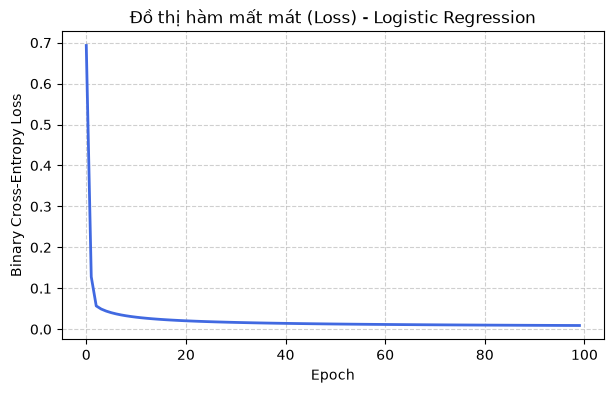

In [3]:
# Huấn luyện mô hình
model_lr = LogisticRegression(lr=0.5, epochs=100)
model_lr.fit(X_train_bin, y_train_bin)

# Dự đoán và tính metrics
y_pred_bin = model_lr.predict(X_test_bin)

tp = np.sum((y_test_bin == 1) & (y_pred_bin == 1))
fp = np.sum((y_test_bin == 0) & (y_pred_bin == 1))
fn = np.sum((y_test_bin == 1) & (y_pred_bin == 0))

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
accuracy = np.mean(y_pred_bin == y_test_bin)

print('Kết quả đánh giá Logistic Regression (NumPy) trên MNIST (0 vs 1):')
print(f'- Accuracy : {accuracy:.4f}')
print(f'- Precision: {precision:.4f}')
print(f'- Recall   : {recall:.4f}')
print(f'- F1-score : {f1:.4f}')

# Vẽ đồ thị loss
plt.figure(figsize=(7, 4))
plt.plot(model_lr.losses, color='royalblue', lw=2)
plt.title('Đồ thị hàm mất mát (Loss) - Logistic Regression')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Assignment 2 (4 scores):

- Use Numpy only to construct the Softmax Regression model.
- Train and evaluating (precision, recall, f1) the Softmax Regression model using the Gradient Descent approach **to classify 10 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [4]:
# Chuẩn bị dữ liệu 10 chữ số
X_train_multi = x_train.reshape(-1, 28 * 28) / 255.0
y_train_multi = y_train
X_test_multi = x_test.reshape(-1, 28 * 28) / 255.0
y_test_multi = y_test

print('Kích thước tập huấn luyện 10 chữ số:', X_train_multi.shape)
print('Kích thước tập kiểm tra 10 chữ số  :', X_test_multi.shape)

Kích thước tập huấn luyện 10 chữ số: (60000, 784)
Kích thước tập kiểm tra 10 chữ số  : (10000, 784)


In [5]:
class SoftmaxRegression:
    def __init__(self, lr=0.5, epochs=100):
        self.lr = lr
        self.epochs = epochs
        self.losses = []

    def _softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.n_classes = len(np.unique(y))
        
        self.W = np.zeros((n_features, self.n_classes))
        self.b = np.zeros(self.n_classes)

        # One-hot encoding
        Y_onehot = np.zeros((n_samples, self.n_classes))
        Y_onehot[np.arange(n_samples), y] = 1

        for epoch in range(self.epochs):
            Z = np.dot(X, self.W) + self.b
            probs = self._softmax(Z)

            loss = -np.mean(np.sum(Y_onehot * np.log(probs + 1e-15), axis=1))
            self.losses.append(loss)

            dW = np.dot(X.T, (probs - Y_onehot)) / n_samples
            db = np.mean(probs - Y_onehot, axis=0)

            self.W -= self.lr * dW
            self.b -= self.lr * db

    def predict(self, X):
        Z = np.dot(X, self.W) + self.b
        return np.argmax(Z, axis=1)

Báo cáo đánh giá Softmax Regression (NumPy) trên 10 chữ số MNIST:
              precision    recall  f1-score   support

           0     0.9293    0.9786    0.9533       980
           1     0.9484    0.9718    0.9600      1135
           2     0.9133    0.8576    0.8846      1032
           3     0.8857    0.8901    0.8879      1010
           4     0.8905    0.9196    0.9048       982
           5     0.8854    0.8229    0.8530       892
           6     0.9227    0.9342    0.9284       958
           7     0.9124    0.8920    0.9021      1028
           8     0.8473    0.8604    0.8538       974
           9     0.8669    0.8712    0.8690      1009

    accuracy                         0.9012     10000
   macro avg     0.9002    0.8998    0.8997     10000
weighted avg     0.9010    0.9012    0.9008     10000



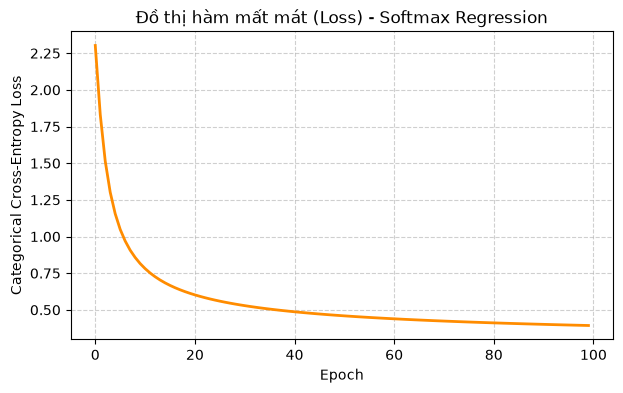

In [6]:
# Huấn luyện mô hình Softmax Regression
model_softmax = SoftmaxRegression(lr=0.5, epochs=100)
model_softmax.fit(X_train_multi, y_train_multi)

# Dự đoán và đánh giá
y_pred_multi = model_softmax.predict(X_test_multi)

from sklearn.metrics import classification_report
print('Báo cáo đánh giá Softmax Regression (NumPy) trên 10 chữ số MNIST:')
print(classification_report(y_test_multi, y_pred_multi, digits=4))

# Vẽ đồ thị loss
plt.figure(figsize=(7, 4))
plt.plot(model_softmax.losses, color='darkorange', lw=2)
plt.title('Đồ thị hàm mất mát (Loss) - Softmax Regression')
plt.xlabel('Epoch')
plt.ylabel('Categorical Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Assignment 3 (2 scores):

- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Logistic Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Softmax Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.

In [7]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import classification_report

# 1. Scikit-Learn Logistic Regression (chữ số 0 và 1)
sk_binary = SklearnLogisticRegression(max_iter=200)
sk_binary.fit(X_train_bin, y_train_bin)
y_pred_sk_bin = sk_binary.predict(X_test_bin)

print('=== Scikit-Learn Logistic Regression (0 vs 1) ===')
print(classification_report(y_test_bin, y_pred_sk_bin, digits=4))

# 2. Scikit-Learn Softmax Regression (10 chữ số)
sk_multi = SklearnLogisticRegression(max_iter=100, solver='lbfgs')
sk_multi.fit(X_train_multi, y_train_multi)
y_pred_sk_multi = sk_multi.predict(X_test_multi)

print('=== Scikit-Learn Softmax Regression (10 chữ số) ===')
print(classification_report(y_test_multi, y_pred_sk_multi, digits=4))

=== Scikit-Learn Logistic Regression (0 vs 1) ===
              precision    recall  f1-score   support

           0     1.0000    0.9990    0.9995       980
           1     0.9991    1.0000    0.9996      1135

    accuracy                         0.9995      2115
   macro avg     0.9996    0.9995    0.9995      2115
weighted avg     0.9995    0.9995    0.9995      2115



=== Scikit-Learn Softmax Regression (10 chữ số) ===
              precision    recall  f1-score   support

           0     0.9514    0.9786    0.9648       980
           1     0.9627    0.9789    0.9707      1135
           2     0.9279    0.8973    0.9123      1032
           3     0.9026    0.9079    0.9052      1010
           4     0.9355    0.9308    0.9331       982
           5     0.9062    0.8778    0.8918       892
           6     0.9373    0.9520    0.9446       958
           7     0.9397    0.9241    0.9318      1028
           8     0.8722    0.8830    0.8776       974
           9     0.9131    0.9167    0.9149      1009

    accuracy                         0.9257     10000
   macro avg     0.9249    0.9247    0.9247     10000
weighted avg     0.9256    0.9257    0.9256     10000



D:\UIT\FOUNDATIONAL SUBJECTS\DS102-Học máy thống kê\Thực Hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
